# E-commerce Product Analysis

## Цель проекта

Исследовать поведение пользователей интернет-магазина от взаимодействия с товарами до покупки, выявить точки потери пользователей и потенциальные зоны улучшения клиентского опыта.

In [1]:
import pandas as pd

## 1. Проверка и подготовка данных

### 1.1 Анализ событий пользователей

Сначала проведём первичный обзор таблицы `events`: проверим структуру данных, качество записей, временной охват и распределение пользовательских событий

In [2]:
events = pd.read_csv("../data/raw/events.csv")

In [3]:
events.head()

,event_id,user_id,product_id,event_type,event_timestamp
0,E00000001,U009798,P001393,cart,2025-07-08T14:28:55.893919
1,E00000002,U005881,P000669,view,2025-10-19T23:00:44.067982
2,E00000003,U006348,P001404,view,2025-05-09T07:02:42.256662
3,E00000004,U002664,P000400,cart,2025-07-19T22:47:07.019634
4,E00000005,U005776,P000392,view,2024-10-24T10:20:33.602165


In [4]:
events['event_type'].unique()

array(['cart', 'view', 'wishlist', 'purchase'], dtype=object)

In [5]:
events.shape

(80000, 5)

In [6]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   event_id         80000 non-null  object
 1   user_id          80000 non-null  object
 2   product_id       80000 non-null  object
 3   event_type       80000 non-null  object
 4   event_timestamp  80000 non-null  object
dtypes: object(5)
memory usage: 3.1+ MB


In [7]:
events.duplicated().sum()

np.int64(0)

In [8]:
events["event_id"].nunique()

80000

In [9]:
events["event_timestamp"] = pd.to_datetime(events["event_timestamp"])

In [10]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   event_id         80000 non-null  object        
 1   user_id          80000 non-null  object        
 2   product_id       80000 non-null  object        
 3   event_type       80000 non-null  object        
 4   event_timestamp  80000 non-null  datetime64[ns]
dtypes: datetime64[ns](1), object(4)
memory usage: 3.1+ MB


In [11]:
events["event_timestamp"].min()


Timestamp('2024-01-01 00:09:40.129008')

In [12]:
events["event_timestamp"].max()

Timestamp('2025-11-14 23:36:10.745951')

In [13]:
events.groupby("event_type").size()

event_type
cart        12035
purchase     4006
view        56013
wishlist     7946
dtype: int64

In [14]:
events["user_id"].nunique()

9995

In [15]:
events.groupby("event_type")["user_id"].nunique()

event_type
cart        6994
purchase    3281
view        9961
wishlist    5504
Name: user_id, dtype: int64

**Первичный вывод**
- В таблице 80 000 событий от 9 995 уникальных пользователей.
- Пропусков и полных дублей не обнаружено.
- event_id уникален.
- Данные охватывают период с 2024-01-01 по 2025-11-14.
- Самое частое событие — view (56 013 событий).
- 9 961 пользователь совершал view, 6 994 — cart,
  5 504 — wishlist, 3 281 — purchase.
- У 34 пользователей нет события view.
- Количество событий нельзя напрямую использовать как пользовательскую конверсию.

In [16]:
events[events['event_type'] == 'cart'].groupby('product_id').size().sort_values(ascending=False).head(10)

product_id
P001938    17
P001112    16
P001086    16
P000233    16
P000967    16
P000604    16
P001689    15
P001651    15
P000268    15
P001815    15
dtype: int64

In [17]:
events[events['event_type'] == 'purchase'] \
    .groupby('product_id') \
    .size() \
    .sort_values(ascending=False) \
    .head(10)

product_id
P001113    8
P000984    8
P000454    7
P001235    7
P000510    7
P001011    7
P000258    7
P000001    6
P000216    6
P000234    6
dtype: int64

In [18]:
cart_counts = (
    events[events['event_type'] == 'cart']
    .groupby('product_id')
    .size()
)

In [19]:
purchase_counts = (
    events[events['event_type'] == 'purchase']
    .groupby('product_id')
    .size()
)

In [20]:
cart_counts.head()

product_id
P000001    5
P000002    4
P000003    7
P000004    3
P000005    4
dtype: int64

In [21]:
purchase_counts.head()

product_id
P000001    6
P000002    1
P000003    2
P000004    1
P000005    1
dtype: int64

In [22]:
product_stats = pd.DataFrame({
    'cart_count': cart_counts,
    'purchase_count': purchase_counts
})

In [23]:
product_stats.head()

,cart_count,purchase_count
product_id,,
P000001,5.0,6.0
P000002,4.0,1.0
P000003,7.0,2.0
P000004,3.0,1.0
P000005,4.0,1.0


In [24]:
product_stats.isna().sum()

cart_count          1
purchase_count    275
dtype: int64

In [25]:
product_stats = product_stats.fillna(0)

In [26]:
product_stats = product_stats.astype(int)

In [27]:
product_stats.head()

,cart_count,purchase_count
product_id,,
P000001,5,6
P000002,4,1
P000003,7,2
P000004,3,1
P000005,4,1


In [28]:
product_stats[
    product_stats['purchase_count'] == 0
].sort_values('cart_count', ascending=False).head(10)

,cart_count,purchase_count
product_id,,
P000604,16,0
P000268,15,0
P001546,13,0
P000970,13,0
P000850,13,0
P001582,12,0
P001691,12,0
P000691,12,0
P000776,12,0


**Промежуточный вывод**

Среди товаров без зарегистрированных `purchase`-событий наибольшее количество `cart`-событий у `P000604` — **16**.

Это может указывать на потенциальную проблему между добавлением товара в корзину и покупкой, однако для вывода о причине необходимо изучить уникальных пользователей и последовательность их действий.

**Следующий шаг:** проверить количество уникальных пользователей для `cart` и `purchase` по товарам.

#### Анализ на уровне уникальных пользователей

Проверим, сохраняется ли картина после перехода от количества событий к количеству уникальных пользователей

In [29]:
cart_users = events[events['event_type'] == 'cart'] \
    .groupby('product_id')['user_id'] \
    .nunique()

In [30]:
purchase_users = events[events['event_type'] == 'purchase'] \
    .groupby('product_id')['user_id'] \
    .nunique()

In [31]:
product_user_stats = pd.DataFrame({
    'cart_users': cart_users,
    'purchase_users': purchase_users
})

In [32]:
product_user_stats.head()

,cart_users,purchase_users
product_id,,
P000001,5.0,6.0
P000002,4.0,1.0
P000003,7.0,2.0
P000004,3.0,1.0
P000005,4.0,1.0


In [33]:
product_user_stats.isna().sum()

cart_users          1
purchase_users    275
dtype: int64

In [34]:
product_user_stats = product_user_stats.fillna(0)
product_user_stats = product_user_stats.astype(int)

In [35]:
product_user_stats.head()

,cart_users,purchase_users
product_id,,
P000001,5,6
P000002,4,1
P000003,7,2
P000004,3,1
P000005,4,1


In [36]:
product_user_stats[
    product_user_stats['purchase_users'] == 0
].sort_values('cart_users', ascending=False).head(10)

,cart_users,purchase_users
product_id,,
P000604,16,0
P000268,15,0
P001546,13,0
P000970,13,0
P000850,13,0
P001582,12,0
P001691,12,0
P000691,12,0
P000776,12,0


**Вывод**

После перехода от количества событий к уникальным пользователям список товаров практически не изменился.

У `P000604` 16 уникальных пользователей добавляли товар в корзину, при этом среди данных отсутствуют пользователи с событием `purchase` для этого товара.

Это подтверждает, что высокий `cart_count` для данного товара не был вызван повторными добавлениями одного пользователя. Товар остаётся кандидатом для дальнейшего анализа пути `cart → purchase`.

### 1.2 Проверка пути `cart → purchase`

Проверим, можно ли восстановить последовательный переход пользователя от добавления товара в корзину к покупке одного и того же товара

Для этого сопоставим события `cart` и `purchase` по `user_id` и `product_id`, а затем проверим временную последовательность событий

In [37]:
cart_events = (
    events[events['event_type'] == 'cart']
    [['user_id', 'product_id', 'event_timestamp']]
    .rename(columns={'event_timestamp': 'cart_time'})
)

In [38]:
purchase_events = (
    events[events['event_type'] == 'purchase']
    [['user_id', 'product_id', 'event_timestamp']]
    .rename(columns={'event_timestamp': 'purchase_time'})
)

In [39]:
cart_purchase = cart_events.merge(
    purchase_events,
    on=['user_id', 'product_id'],
    how='inner'
)

In [40]:
cart_purchase.head()

,user_id,product_id,cart_time,purchase_time
0,U006386,P000896,2025-06-03 03:50:34.383518,2024-05-12 01:57:58.848529


In [41]:
valid_cart_purchase = cart_purchase[
    cart_purchase['purchase_time'] > cart_purchase['cart_time']
]

In [42]:
valid_cart_purchase.shape

(0, 4)

In [43]:
valid_cart_purchase.head()

,user_id,product_id,cart_time,purchase_time


**Вывод**

После сопоставления событий `cart` и `purchase` по одинаковым `user_id` и `product_id` и проверки условия `purchase_time > cart_time` валидных последовательностей `cart → purchase` обнаружено не было

Следовательно, таблица `events` в текущем виде не позволяет корректно построить товарную воронку `cart → purchase`. Количества событий `cart` и `purchase` нельзя интерпретировать как последовательную конверсию

Дальнейший анализ покупательского поведения будет строиться с использованием таблиц `orders` и `order_items`, а `events` — использоваться для описательного анализа пользовательских действий

### 1.3 Проверка `orders` и `order_items`

In [44]:
import pandas as pd

orders = pd.read_csv('../data/raw/orders.csv')
order_items = pd.read_csv('../data/raw/order_items.csv')

In [45]:
orders.head()

,order_id,user_id,order_date,order_status,total_amount
0,O00000001,U009310,2025-09-09T14:52:37.292731,processing,689.66
1,O00000002,U003247,2025-04-15T01:18:27.193404,completed,1666.85
2,O00000003,U007252,2025-04-27T15:37:48.008624,processing,665.06
3,O00000004,U008986,2025-10-04T20:35:22.204857,cancelled,689.50
4,O00000005,U008537,2024-11-13T08:15:18.498252,cancelled,860.50


In [46]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   order_id      20000 non-null  object 
 1   user_id       20000 non-null  object 
 2   order_date    20000 non-null  object 
 3   order_status  20000 non-null  object 
 4   total_amount  20000 non-null  float64
dtypes: float64(1), object(4)
memory usage: 781.4+ KB


In [47]:
orders['order_date'] = pd.to_datetime(orders['order_date'])

In [48]:
orders['order_date'].dtype

dtype('<M8[ns]')

In [49]:
print('unique order_id:', orders['order_id'].nunique())
print('duplicates:', orders.duplicated().sum())
print(orders['order_status'].value_counts())

unique order_id: 20000
duplicates: 0
order_status
shipped       4113
returned      4066
completed     4021
cancelled     3920
processing    3880
Name: count, dtype: int64


In [50]:
order_items.head()

,order_item_id,order_id,product_id,user_id,quantity,item_price,item_total
0,I00000001,O00000001,P001758,U009310,2,8.07,16.14
1,I00000002,O00000001,P001119,U009310,1,74.08,74.08
2,I00000003,O00000001,P001794,U009310,1,576.97,576.97
3,I00000004,O00000001,P001038,U009310,1,22.47,22.47
4,I00000005,O00000002,P000859,U003247,1,422.22,422.22


#### Согласованность сумм `orders` и `order_items`

Проверим, совпадает ли сумма товарных позиций каждого заказа из `order_items` с `total_amount` из `orders`

In [51]:
items_by_order = (
    order_items
    .groupby('order_id')['item_total']
    .sum()
    .reset_index(name='items_sum')
)

order_check = orders.merge(
    items_by_order,
    on='order_id',
    how='left'
)

order_check['difference'] = (
    order_check['total_amount'] - order_check['items_sum']
).round(2)

In [52]:
order_check['difference'].value_counts().head(10)

difference
-0.0    20000
Name: count, dtype: int64

**Вывод**

Для каждого заказа была рассчитана сумма товарных позиций из `order_items` и сопоставлена с `total_amount` из `orders`

Расхождений не обнаружено: для всех 20 000 заказов сумма `item_total` полностью совпадает с `total_amount`

Это подтверждает согласованность данных между таблицами и позволяет использовать `orders` для анализа заказов и выручки, а `order_items` — для анализа товаров и состава заказов

#### Проверка качества `order_items`

Проверим структуру таблицы, уникальность товарных позиций, наличие дубликатов и арифметическую согласованность стоимости товаров

In [53]:
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43525 entries, 0 to 43524
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_item_id  43525 non-null  object 
 1   order_id       43525 non-null  object 
 2   product_id     43525 non-null  object 
 3   user_id        43525 non-null  object 
 4   quantity       43525 non-null  int64  
 5   item_price     43525 non-null  float64
 6   item_total     43525 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 2.3+ MB


In [54]:
print('unique order_item_id:', order_items['order_item_id'].nunique())
print('duplicates:', order_items.duplicated().sum())

item_difference = (
    order_items['item_total']
    - order_items['quantity'] * order_items['item_price']
).round(2)

print(item_difference.value_counts().head())

unique order_item_id: 43525
duplicates: 0
0.0    43525
Name: count, dtype: int64


**Вывод**

Таблица содержит 43 525 товарных позиций

`order_item_id` уникален для каждой строки, полные дубликаты и пропуски отсутствуют

Дополнительно была проверена арифметическая согласованность товарных позиций:

`item_total = quantity × item_price`

Расхождений не обнаружено для всех 43 525 строк

#### Проверка связей между `orders` и `order_items`

Дополнительно проверим, совпадает ли пользователь товарной позиции с пользователем соответствующего заказа

In [55]:
user_check = order_items.merge(
    orders[['order_id', 'user_id']],
    on='order_id',
    how='left',
    suffixes=('_item', '_order')
)

user_check.head()

,order_item_id,order_id,product_id,user_id_item,quantity,item_price,item_total,user_id_order
0,I00000001,O00000001,P001758,U009310,2,8.07,16.14,U009310
1,I00000002,O00000001,P001119,U009310,1,74.08,74.08,U009310
2,I00000003,O00000001,P001794,U009310,1,576.97,576.97,U009310
3,I00000004,O00000001,P001038,U009310,1,22.47,22.47,U009310
4,I00000005,O00000002,P000859,U003247,1,422.22,422.22,U003247


In [56]:
mismatched_users = user_check[
    user_check['user_id_item'] != user_check['user_id_order']
]

mismatched_users.shape

(0, 8)

**Вывод**

Дополнительно была проверена согласованность пользователей между таблицами

Для всех 43 525 товарных позиций `user_id` совпадает с пользователем соответствующего заказа в `orders`

Таким образом, связь между таблицами согласована по `order_id`, пользователю и сумме заказа

### 1.4 Временной охват данных

Проверим период, за который представлены заказы, чтобы корректно интерпретировать дальнейшую динамику показателей

In [57]:
orders['order_date'].agg(['min', 'max'])

min   2024-01-01 00:14:17.631198
max   2025-11-14 23:17:25.548939
Name: order_date, dtype: datetime64[ns]

**Вывод**

Заказы представлены за период с 1 января 2024 года по 14 ноября 2025 года

Последний месяц представлен не полностью, поэтому ноябрь 2025 нельзя напрямую сравнивать с полными календарными месяцами без дополнительной корректировки

## 2. Анализ завершённых заказов

### 2.1 Базовые метрики завершённых заказов

Сначала рассчитаем основные коммерческие показатели по завершённым заказам: количество заказов и покупателей, GMV и среднюю стоимость заказа

In [58]:
completed_orders = orders[
    orders['order_status'] == 'completed'
].copy()

summary = pd.Series({
    'completed_orders': completed_orders['order_id'].nunique(),
    'buyers': completed_orders['user_id'].nunique(),
    'gmv': completed_orders['total_amount'].sum(),
    'avg_order_value': completed_orders['total_amount'].mean()
})

summary.round(2)

completed_orders       4021.00
buyers                 3320.00
gmv                 2419712.58
avg_order_value         601.77
dtype: float64

**Вывод**

За анализируемый период было совершено 4 021 завершённый заказ от 3 320 уникальных покупателей

GMV завершённых заказов составил 2 419 712.58, средний чек — 601.77

Количество заказов превышает количество покупателей, что указывает на наличие повторных покупок. Далее необходимо оценить их долю и частоту

### 2.2 Повторные покупки

Проверим, сколько завершённых заказов приходится на одного покупателя и какую долю покупателей составляют пользователи с двумя и более покупками

In [59]:
orders_per_user = (
    completed_orders
    .groupby('user_id')['order_id']
    .nunique()
    .sort_values(ascending=False)
)

orders_per_user.head(10)

user_id
U009071    4
U003576    4
U004903    4
U008345    4
U000441    3
U002773    3
U009781    3
U008082    3
U000524    3
U004898    3
Name: order_id, dtype: int64

In [60]:
order_frequency = orders_per_user.value_counts().sort_index()

order_frequency

order_id
1    2708
2     527
3      81
4       4
Name: count, dtype: int64

In [61]:
repeat_buyers = (orders_per_user >= 2).sum()
repeat_rate = (orders_per_user >= 2).mean() * 100

print('repeat_buyers:', repeat_buyers)
print('repeat_rate:', round(repeat_rate, 2))

repeat_buyers: 612
repeat_rate: 18.43


**Вывод**

Из 3 320 уникальных покупателей 612 совершили минимум две завершённые покупки

Repeat rate составил 18.43%

Большинство покупателей совершили только одну завершённую покупку

Сам по себе этот показатель не позволяет оценить качество удержания без дополнительного бизнес-контекста и сравнительного периода, поэтому далее рассмотрим интервалы между повторными покупками

### 2.3 Интервалы между повторными покупками

Для покупателей с несколькими завершёнными заказами рассчитаем время между последовательными покупками

Для этого отсортируем покупки каждого пользователя по времени и получим дату предыдущего заказа

In [62]:
completed_orders_sorted = (
    completed_orders
    .sort_values(['user_id', 'order_date'])
    .copy()
)

completed_orders_sorted['prev_order_date'] = (
    completed_orders_sorted
    .groupby('user_id')['order_date']
    .shift(1)
)

In [63]:
completed_orders_sorted['days_since_prev'] = (
    completed_orders_sorted['order_date']
    - completed_orders_sorted['prev_order_date']
).dt.days

In [64]:
completed_orders_sorted['days_since_prev'].describe()

count    701.000000
mean     201.987161
std      146.330687
min        0.000000
25%       81.000000
50%      171.000000
75%      308.000000
max      673.000000
Name: days_since_prev, dtype: float64

**Уточняющая проверка**

Минимальный интервал при расчёте через `.dt.days` оказался равен 0. Проверим такие наблюдения подробнее, поскольку `.dt.days` отбрасывает неполную часть суток

In [65]:
completed_orders_sorted[
    completed_orders_sorted['days_since_prev'] == 0
][
    ['user_id', 'prev_order_date', 'order_date', 'days_since_prev']
].head(10)

,user_id,prev_order_date,order_date,days_since_prev
8462,U002117,2024-11-01 21:17:49.186913,2024-11-02 05:48:26.828104,0.0
11950,U003032,2025-03-30 14:32:57.760069,2025-03-31 05:35:06.878300,0.0
1039,U003610,2025-05-15 18:32:32.574112,2025-05-16 15:02:33.880923,0.0


In [66]:
(completed_orders_sorted['days_since_prev'] == 0).sum()

np.int64(3)

In [67]:
completed_orders_sorted['days_since_prev_exact'] = (
    completed_orders_sorted['order_date']
    - completed_orders_sorted['prev_order_date']
).dt.total_seconds() / 86400

In [68]:
completed_orders_sorted['days_since_prev_exact'].describe()

count    701.000000
mean     202.459541
std      146.345689
min        0.354602
25%       81.521942
50%      171.091579
75%      308.363897
max      673.638496
Name: days_since_prev_exact, dtype: float64

**Вывод**

Всего рассчитан 701 интервал между повторными покупками

Медианный интервал составляет около 171 дня, средний — около 202 дней

Половина наблюдаемых интервалов находится примерно между 82 и 308 днями. Среднее значение выше медианы, что указывает на наличие длинного правого хвоста

Минимальный точный интервал составляет около 0.35 дня. Ранее полученные значения 0 возникали из-за округления неполных суток методом `.dt.days`

Расчёт относится только к наблюдаемым повторным покупкам и не учитывает возможные будущие покупки после окончания периода наблюдения

### 2.4 Динамика ключевых метрик завершённых заказов

Рассмотрим помесячную динамику завершённых заказов, покупателей, GMV и средней стоимости заказа

Ноябрь 2025 года является неполным месяцем, поэтому исключим его из сравнительного анализа полных календарных месяцев

In [69]:
completed_orders['month'] = (
    completed_orders['order_date']
    .dt.to_period('M')
)

In [70]:
completed_orders[
    ['order_date', 'month']
].head()

,order_date,month
1,2025-04-15 01:18:27.193404,2025-04
5,2024-10-13 09:02:26.848944,2024-10
7,2024-03-03 23:33:22.844913,2024-03
19,2024-07-13 06:57:25.769991,2024-07
20,2025-07-30 08:08:33.421591,2025-07


In [71]:
monthly_metrics = (
    completed_orders
    .groupby('month')
    .agg(
        completed_orders=('order_id', 'nunique'),
        buyers=('user_id', 'nunique'),
        gmv=('total_amount', 'sum'),
        avg_order_value=('total_amount', 'mean')
    )
    .reset_index()
)

monthly_metrics['gmv'] = monthly_metrics['gmv'].round(2)
monthly_metrics['avg_order_value'] = monthly_metrics['avg_order_value'].round(2)

monthly_metrics

,month,completed_orders,buyers,gmv,avg_order_value
0,2024-01,167,167,95429.66,571.44
1,2024-02,147,146,73319.35,498.77
2,2024-03,213,212,134569.53,631.78
3,2024-04,190,188,103610.56,545.32
4,2024-05,169,167,115249.52,681.95
5,2024-06,191,191,126550.29,662.57
6,2024-07,186,185,108635.16,584.06
7,2024-08,190,189,91515.76,481.66
8,2024-09,168,167,96088.95,571.96
9,2024-10,185,183,113797.42,615.12


In [72]:
monthly_full = monthly_metrics[
    monthly_metrics['month'] != pd.Period('2025-11', freq='M')
].copy()

monthly_full['month_dt'] = monthly_full['month'].dt.to_timestamp()

In [73]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [74]:
import matplotlib.pyplot as plt

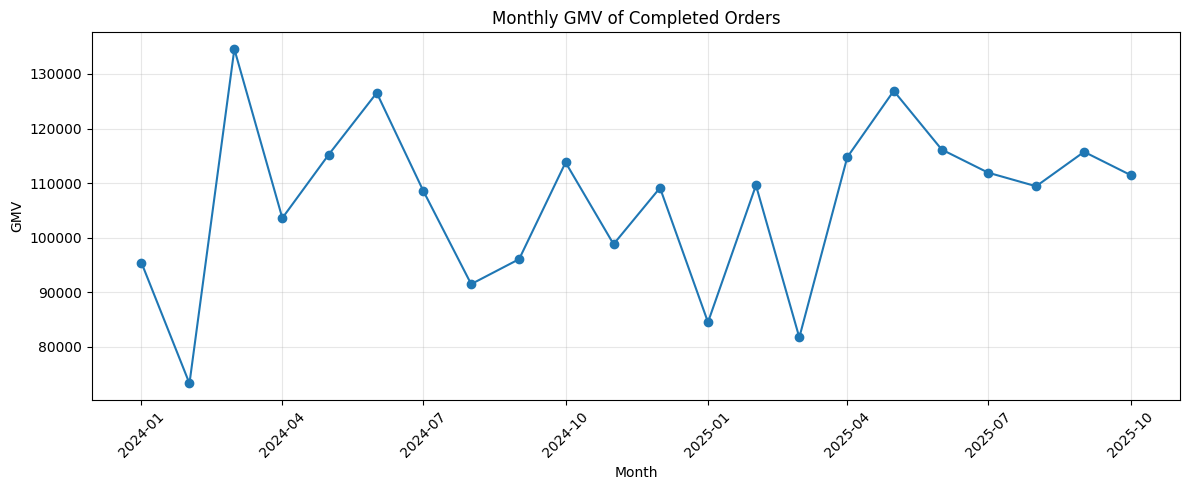

In [75]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_full['month_dt'],
    monthly_full['gmv'],
    marker='o'
)

plt.title('Monthly GMV of Completed Orders')
plt.xlabel('Month')
plt.ylabel('GMV')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('../images/monthly_gmv.png', dpi=150, bbox_inches='tight')

plt.show()

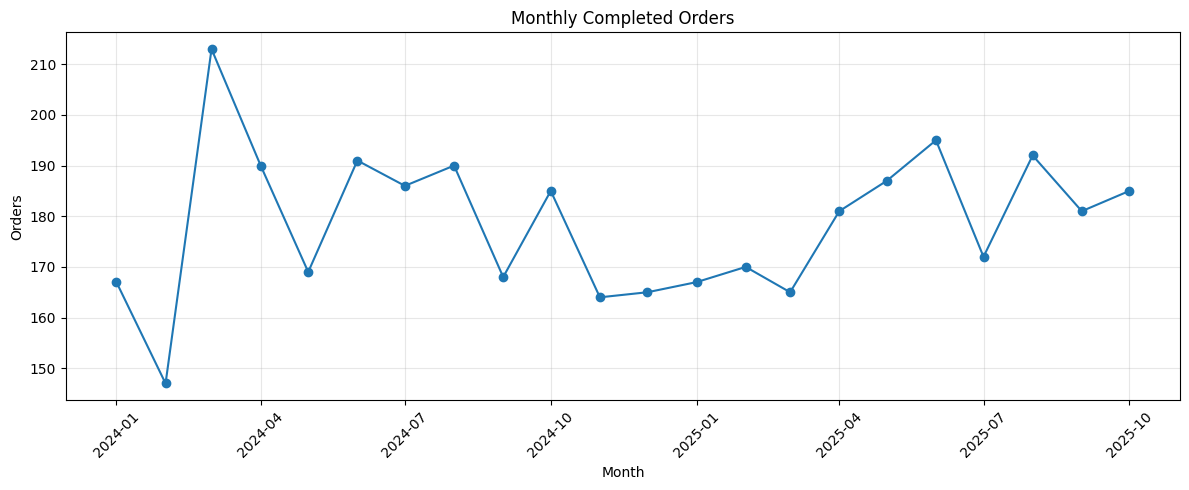

In [76]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_full['month_dt'],
    monthly_full['completed_orders'],
    marker='o'
)

plt.title('Monthly Completed Orders')
plt.xlabel('Month')
plt.ylabel('Orders')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('../images/monthly_completed_orders.png', dpi=150, bbox_inches='tight')

plt.show()

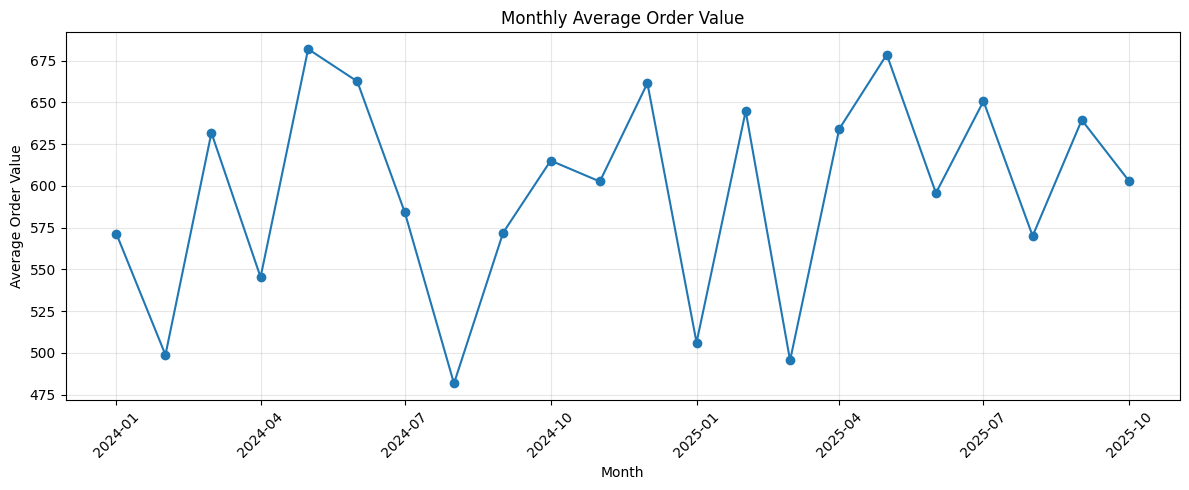

In [77]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_full['month_dt'],
    monthly_full['avg_order_value'],
    marker='o'
)

plt.title('Monthly Average Order Value')
plt.xlabel('Month')
plt.ylabel('Average Order Value')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('../images/monthly_aov.png', dpi=150, bbox_inches='tight')

plt.show()

**Вывод**

По полным месяцам 2024–2025 годов GMV заметно колеблется, однако устойчивого долгосрочного роста или снижения не наблюдается

Максимальный GMV среди полных месяцев зафиксирован в марте 2024 года — около 134.6 тыс. В этом же месяце наблюдается максимальное количество завершённых заказов — 213, поэтому высокий GMV в значительной степени связан с большим количеством заказов

При этом изменения GMV зависят не только от количества заказов, но и от средней стоимости заказа. Например, в мае 2024 и мае 2025 средний чек был одним из самых высоких — около 682 и 679 соответственно

Наиболее низкие значения среднего чека наблюдались в августе 2024 и марте 2025 — около 482 и 495

Таким образом, изменения GMV по месяцам определяются одновременно количеством завершённых заказов и их средней стоимостью

Ноябрь 2025 года исключён из сравнительного анализа, поскольку данные представлены только до 14 ноября

## 3. Анализ товаров и категорий

### 3.1 Проверка качества `products`

Проведём базовую проверку справочника товаров: оценим структуру таблицы, уникальность `product_id`, наличие дубликатов и пропусков, а также диапазоны цен и рейтингов

In [78]:
products = pd.read_csv('../data/raw/products.csv')

products.head()

,product_id,product_name,category,brand,price,rating
0,P000001,Astra Be,Clothing,Astra,157.89,4.08
1,P000002,NeoTech Someone,Groceries,NeoTech,21.46,3.87
2,P000003,Acme Discuss,Sports,Acme,265.37,3.46
3,P000004,Nimbus South,Electronics,Nimbus,541.41,4.14
4,P000005,Astra Capital,Home & Kitchen,Astra,198.00,3.97


In [79]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    2000 non-null   object 
 1   product_name  2000 non-null   object 
 2   category      2000 non-null   object 
 3   brand         2000 non-null   object 
 4   price         2000 non-null   float64
 5   rating        2000 non-null   float64
dtypes: float64(2), object(4)
memory usage: 93.9+ KB


In [80]:
products.columns

Index(['product_id', 'product_name', 'category', 'brand', 'price', 'rating'], dtype='object')

In [81]:
print('unique product_id:', products['product_id'].nunique())
print('duplicates:', products.duplicated().sum())

print('\nCategories:')
print(products['category'].value_counts())

print('\nPrice range:')
print(products['price'].agg(['min', 'max']))

print('\nRating range:')
print(products['rating'].agg(['min', 'max']))

unique product_id: 2000
duplicates: 0

Categories:
category
Clothing          213
Toys              213
Pet Supplies      212
Beauty            207
Electronics       203
Home & Kitchen    199
Books             194
Automotive        193
Groceries         183
Sports            183
Name: count, dtype: int64

Price range:
min       1.11
max    2338.13
Name: price, dtype: float64

Rating range:
min    2.5
max    4.9
Name: rating, dtype: float64


**Вывод**

Таблица содержит 2 000 уникальных товаров

`product_id` уникален для каждой строки, полные дубликаты и пропуски отсутствуют

Товары распределены по 10 категориям относительно равномерно

Диапазон цен составляет от 1.11 до 2 338.13, рейтинг товаров — от 2.5 до 4.9

Критичных аномалий на базовом уровне проверки не обнаружено

### 3.2 Структура продаж по категориям

Объединим товарные позиции завершённых заказов со справочником товаров и оценим вклад категорий в GMV, количество проданных единиц, заказов и покупателей

In [82]:
completed_items = (
    order_items
    .merge(
        completed_orders[['order_id', 'order_date']],
        on='order_id',
        how='inner'
    )
    .merge(
        products,
        on='product_id',
        how='left'
    )
)

completed_items.head()

,order_item_id,order_id,product_id,user_id,quantity,item_price,item_total,order_date,product_name,category,brand,price,rating
0,I00000005,O00000002,P000859,U003247,1,422.22,422.22,2025-04-15 01:18:27.193404,Pulse Decide,Electronics,Pulse,422.22,3.51
1,I00000006,O00000002,P000803,U003247,1,953.03,953.03,2025-04-15 01:18:27.193404,GreenLeaf Item,Electronics,GreenLeaf,953.03,3.43
2,I00000007,O00000002,P000324,U003247,1,60.11,60.11,2025-04-15 01:18:27.193404,Harbor Visit,Toys,Harbor,60.11,3.20
3,I00000008,O00000002,P000454,U003247,1,231.49,231.49,2025-04-15 01:18:27.193404,Solace Different,Home & Kitchen,Solace,231.49,3.58
4,I00000018,O00000006,P000054,U003449,3,435.87,1307.61,2024-10-13 09:02:26.848944,GreenLeaf Hair,Automotive,GreenLeaf,435.87,4.04


In [83]:
completed_items.shape

(8733, 13)

In [84]:
completed_items[
    ['product_name', 'category', 'brand']
].isna().sum()

product_name    0
category        0
brand           0
dtype: int64

In [85]:
category_metrics = (
    completed_items
    .groupby('category')
    .agg(
        gmv=('item_total', 'sum'),
        units_sold=('quantity', 'sum'),
        orders=('order_id', 'nunique'),
        buyers=('user_id', 'nunique')
    )
    .reset_index()
)

category_metrics['gmv'] = category_metrics['gmv'].round(2)

category_metrics['gmv_share_pct'] = (
    category_metrics['gmv']
    / category_metrics['gmv'].sum()
    * 100
).round(2)

category_metrics = (
    category_metrics
    .sort_values('gmv', ascending=False)
    .reset_index(drop=True)
)

category_metrics

,category,gmv,units_sold,orders,buyers,gmv_share_pct
0,Electronics,966339.61,1164,757,728,39.94
1,Automotive,544953.38,1264,804,773,22.52
2,Home & Kitchen,236094.67,1239,801,776,9.76
3,Sports,193365.43,1138,764,743,7.99
4,Clothing,143476.51,1284,818,793,5.93
5,Beauty,114908.40,1294,857,823,4.75
6,Toys,81246.92,1324,844,815,3.36
7,Pet Supplies,69536.28,1329,832,797,2.87
8,Books,53178.14,1164,769,743,2.20
9,Groceries,16613.24,1026,684,659,0.69


**Вывод**

Категории заметно отличаются по вкладу в GMV

На Electronics приходится 39.94% GMV завершённых заказов, на Automotive — 22.52%. Вместе две категории формируют 62.46% общего GMV

При этом высокий денежный вклад не всегда связан с большим количеством проданных единиц. Beauty, Toys и Pet Supplies имеют сопоставимый или более высокий объём продаж в штуках, но значительно меньший вклад в GMV

Особенно заметно это для Groceries: категория включает более 1 000 проданных единиц, но формирует менее 1% GMV

Это указывает на различия в стоимости товаров между категориями, которые проверим далее

### 3.3 Влияние цены категории на GMV

Проверим, объясняется ли высокий вклад отдельных категорий в GMV более высокой стоимостью товаров

Для сравнения используем среднюю и медианную цену проданной единицы товара

In [86]:
category_price_metrics = (
    completed_items
    .groupby('category')
    .agg(
        avg_item_price=('item_price', 'mean'),
        median_item_price=('item_price', 'median')
    )
    .round(2)
    .sort_values('median_item_price', ascending=False)
)

category_price_metrics

,avg_item_price,median_item_price
category,,
Electronics,831.50,788.21
Automotive,430.18,383.26
Home & Kitchen,191.44,180.70
Sports,172.11,165.03
Clothing,111.34,105.35
Beauty,89.18,83.98
Toys,60.91,56.37
Pet Supplies,52.36,48.74
Books,45.58,46.57


**Вывод**

Высокий вклад Electronics и Automotive в GMV объясняется прежде всего более высокой стоимостью товаров, а не максимальным количеством проданных единиц

Медианная цена товара в Electronics составляет около 788, в Automotive — около 383

Для сравнения, медианная цена в Groceries составляет около 16, в Pet Supplies — около 49, в Toys — около 56

Таким образом, категории с более низкой стоимостью товаров могут иметь высокий объём продаж в штуках, но при этом формировать значительно меньшую долю GMV

Это подтверждает необходимость одновременно учитывать денежный вклад, объём продаж и ценовую структуру категорий

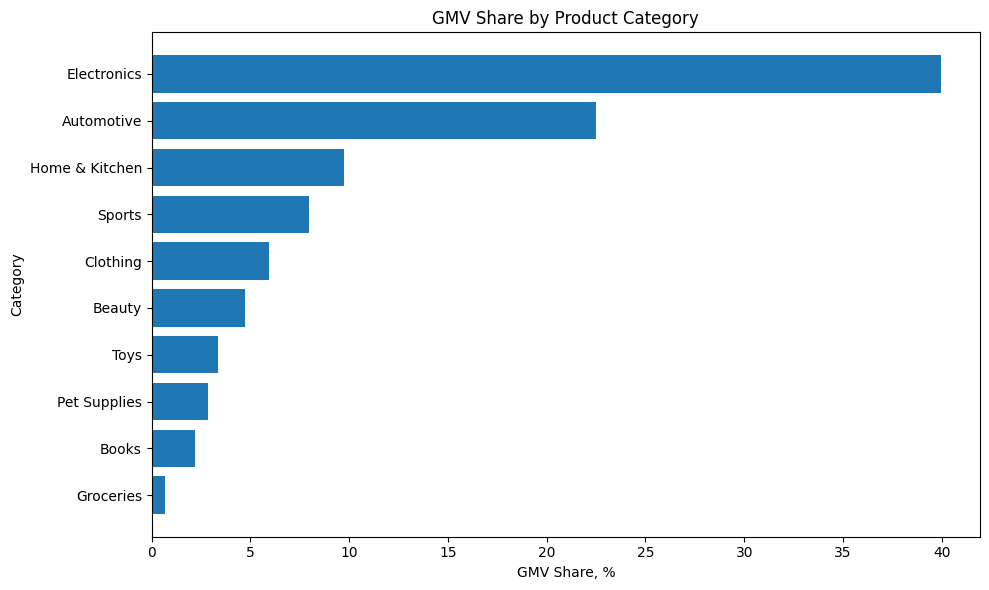

In [87]:
category_plot = category_metrics.sort_values(
    'gmv_share_pct',
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    category_plot['category'],
    category_plot['gmv_share_pct']
)

plt.title('GMV Share by Product Category')
plt.xlabel('GMV Share, %')
plt.ylabel('Category')
plt.tight_layout()

plt.savefig('../images/gmv_share_by_category.png', dpi=150, bbox_inches='tight')

plt.show()

### 3.4 Концентрация GMV внутри Electronics

Перейдём от уровня категорий к отдельным товарам и проверим, зависит ли высокий GMV Electronics от небольшого числа лидирующих SKU

In [88]:
product_metrics = (
    completed_items
    .groupby(['product_id', 'product_name', 'category'])
    .agg(
        gmv=('item_total', 'sum'),
        units_sold=('quantity', 'sum'),
        orders=('order_id', 'nunique'),
        buyers=('user_id', 'nunique')
    )
    .reset_index()
)

product_metrics['gmv'] = product_metrics['gmv'].round(2)

top_products = (
    product_metrics
    .sort_values('gmv', ascending=False)
    .head(10)
)

top_products

,product_id,product_name,category,gmv,units_sold,orders,buyers
1503,P001527,Willow Result,Electronics,18318.78,9,6,6
1865,P001892,Willow Need,Electronics,15455.40,12,8,8
1127,P001143,Orion Number,Electronics,14723.83,11,7,7
544,P000555,Acme Of,Electronics,14076.10,10,7,7
719,P000731,Pulse Treat,Electronics,13600.62,11,8,8
1098,P001113,Pulse Interesting,Electronics,13304.96,8,5,5
999,P001012,Acme Him,Electronics,12902.00,10,5,5
1165,P001183,Nimbus Word,Electronics,12847.24,7,6,6
1068,P001081,Astra Act,Electronics,12809.55,13,10,10
346,P000354,Pulse Letter,Electronics,12486.51,9,6,6


In [89]:
electronics_gmv = (
    product_metrics[
        product_metrics['category'] == 'Electronics'
    ]['gmv']
    .sum()
)

top10_electronics_gmv = (
    product_metrics[
        product_metrics['category'] == 'Electronics'
    ]
    .sort_values('gmv', ascending=False)
    .head(10)['gmv']
    .sum()
)

top10_share = top10_electronics_gmv / electronics_gmv * 100

print('Electronics GMV:', round(electronics_gmv, 2))
print('Top-10 Electronics GMV:', round(top10_electronics_gmv, 2))
print('Top-10 share:', round(top10_share, 2), '%')

Electronics GMV: 966339.61
Top-10 Electronics GMV: 140524.99
Top-10 share: 14.54 %


**Вывод**

Все 10 лидирующих товаров по GMV относятся к категории Electronics

При этом топ-10 товаров формируют только 14.54% GMV категории

Следовательно, высокий денежный вклад Electronics не определяется несколькими отдельными товарами, а распределён между большим количеством SKU

Это снижает риск того, что лидерство категории объясняется единичными аномально дорогими или популярными товарами

### 3.5 Связь рейтинга товара с продажами

Проверим, наблюдается ли линейная связь между рейтингом товара, количеством проданных единиц и GMV

In [90]:
product_rating_sales = (
    product_metrics
    .merge(
        products[['product_id', 'rating']],
        on='product_id',
        how='left'
    )
)

product_rating_sales[
    ['rating', 'units_sold', 'gmv']
].corr().round(3)

,rating,units_sold,gmv
rating,1.000,0.016,0.003
units_sold,0.016,1.000,0.318
gmv,0.003,0.318,1.000


**Вывод**

Корреляция рейтинга товара с количеством проданных единиц составляет 0.016, а с GMV — 0.003

В имеющихся данных практически не наблюдается линейной связи между рейтингом товара и его коммерческими результатами

Корреляция между количеством проданных единиц и GMV составляет 0.318. Связь положительная, но не сильная, поскольку денежный вклад товара зависит не только от количества продаж, но и от его цены

Полученный результат не позволяет утверждать, что рейтинг не влияет на продажи вообще: возможны нелинейные зависимости и различия между категориями, однако выраженной линейной связи в текущих данных не обнаружено

## 4. Дополнительные проверки качества данных

### 4.1 Проверка согласованности `users` и `orders`

Проверим качество таблицы пользователей и согласованность её связи с заказами

Особое внимание уделим временной последовательности: дата заказа должна наступать не раньше даты регистрации пользователя

In [91]:
users = pd.read_csv('../data/raw/users.csv')

users.head()

,user_id,name,email,gender,city,signup_date
0,U000001,Angel Hill,donaldgarcia@example.net,Other,New Roberttown,2025-03-13
1,U000002,Jesse Guzman,jennifermiles@example.com,Male,South Bridget,2024-03-05
2,U000003,Adam Shaffer,jpeterson@example.org,Male,Curtisfurt,2025-07-07
3,U000004,Melanie Munoz,blairamanda@example.com,Other,New Kellystad,2024-03-07
4,U000005,Janet Williams,kendragalloway@example.org,Female,South Joshuastad,2025-01-29


In [92]:
users.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      10000 non-null  object
 1   name         10000 non-null  object
 2   email        10000 non-null  object
 3   gender       10000 non-null  object
 4   city         10000 non-null  object
 5   signup_date  10000 non-null  object
dtypes: object(6)
memory usage: 468.9+ KB


In [93]:
users['signup_date'] = pd.to_datetime(users['signup_date'])

print('unique user_id:', users['user_id'].nunique())
print('duplicates:', users.duplicated().sum())

print('\nSignup date range:')
print(users['signup_date'].agg(['min', 'max']))

print('\nGender:')
print(users['gender'].value_counts())

unique user_id: 10000
duplicates: 0

Signup date range:
min   2024-01-01
max   2025-11-14
Name: signup_date, dtype: datetime64[ns]

Gender:
gender
Other     3419
Female    3334
Male      3247
Name: count, dtype: int64


In [94]:
orders_users_check = orders.merge(
    users[['user_id', 'signup_date']],
    on='user_id',
    how='left'
)

print(
    'Orders without user:',
    orders_users_check['signup_date'].isna().sum()
)

print(
    'Orders before signup:',
    (
        orders_users_check['order_date']
        < orders_users_check['signup_date']
    ).sum()
)

Orders without user: 0
Orders before signup: 9930


**Вывод**

Таблица `users` содержит 10 000 уникальных пользователей без полных дубликатов и пропусков

Все пользователи из `orders` успешно находятся в таблице `users`, поэтому связь по `user_id` технически согласована

Однако для 9 930 заказов дата заказа предшествует дате регистрации пользователя

Из-за нарушения временной последовательности `signup_date` нельзя надёжно использовать для анализа конверсии после регистрации, времени до первой покупки или когортного анализа

Поэтому дальнейший анализ поведения пользователей основан на фактической истории заказов, а не на дате регистрации

### 4.2 Проверка качества `reviews`

Проверим качество отзывов и согласованность их связей с заказами, пользователями и товарами

Дополнительно проверим временную последовательность: отзыв должен быть оставлен после соответствующего заказа

In [95]:
reviews = pd.read_csv('../data/raw/reviews.csv')

reviews.head()

,review_id,order_id,product_id,user_id,rating,review_text,review_date
0,R00000528,O00000237,P001326,U001094,2,Color was different from images.,2025-10-14T12:03:56.749446
1,R00005792,O00002627,P000329,U001858,4,Highly recommend this brand.,2024-10-09T08:04:50.171793
2,R00036604,O00016798,P001160,U008109,4,Highly recommend this brand.,2024-06-03T05:11:16.787214
3,R00040163,O00018414,P001427,U006835,5,Highly recommend this brand.,2024-02-12T06:41:50.215810
4,R00031127,O00014300,P001639,U007148,3,Item arrived damaged.,2025-01-20T05:32:09.398860


In [96]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_id    15000 non-null  object
 1   order_id     15000 non-null  object
 2   product_id   15000 non-null  object
 3   user_id      15000 non-null  object
 4   rating       15000 non-null  int64 
 5   review_text  15000 non-null  object
 6   review_date  15000 non-null  object
dtypes: int64(1), object(6)
memory usage: 820.4+ KB


In [97]:
reviews.columns

Index(['review_id', 'order_id', 'product_id', 'user_id', 'rating',
       'review_text', 'review_date'],
      dtype='object')

In [98]:
reviews['review_date'] = pd.to_datetime(reviews['review_date'])

print('unique review_id:', reviews['review_id'].nunique())
print('duplicates:', reviews.duplicated().sum())

print('\nRating distribution:')
print(reviews['rating'].value_counts().sort_index())

print('\nReview date range:')
print(reviews['review_date'].agg(['min', 'max']))

unique review_id: 15000
duplicates: 0

Rating distribution:
rating
1     594
2    2084
3    4289
4    4624
5    3409
Name: count, dtype: int64

Review date range:
min   2024-01-01 01:23:05.575719
max   2025-11-14 23:26:42.246933
Name: review_date, dtype: datetime64[ns]


In [99]:
review_order_check = reviews.merge(
    orders[['order_id', 'user_id', 'order_date', 'order_status']],
    on='order_id',
    how='left',
    suffixes=('_review', '_order')
)

print(
    'Reviews without order:',
    review_order_check['order_date'].isna().sum()
)

print(
    'User mismatches:',
    (
        review_order_check['user_id_review']
        != review_order_check['user_id_order']
    ).sum()
)

print(
    'Reviews before order:',
    (
        review_order_check['review_date']
        < review_order_check['order_date']
    ).sum()
)

Reviews without order: 0
User mismatches: 0
Reviews before order: 7455


In [100]:
purchased_products = (
    order_items[
        ['order_id', 'product_id', 'user_id']
    ]
    .drop_duplicates()
    .assign(product_in_order=True)
)

review_product_check = reviews.merge(
    purchased_products,
    on=['order_id', 'product_id', 'user_id'],
    how='left'
)

print(
    'Reviews for products not found in order:',
    review_product_check['product_in_order'].isna().sum()
)

Reviews for products not found in order: 0


**Вывод**

Таблица содержит 15 000 уникальных отзывов без полных дубликатов и пропусков

Связи между таблицами технически согласованы: каждый отзыв относится к существующему заказу, `user_id` совпадает с пользователем заказа, а указанный товар действительно присутствует в соответствующем заказе

При этом для 7 455 отзывов, или примерно 49.7% всех записей, дата отзыва предшествует дате заказа

Это нарушает естественную временную последовательность покупки и обратной связи. Поэтому `review_date` нельзя надёжно использовать для анализа поведения после покупки, а данные `reviews` исключены из основных продуктовых выводов проекта

Этот результат дополнительно показывает необходимость проверки не только пропусков и дубликатов, но и логической согласованности данных между таблицами

## 5. Итоговые выводы

В рамках проекта были исследованы пользовательские события, завершённые заказы, товарные позиции, характеристики товаров, поведение покупателей и качество связанных данных

### 5.1 Коммерческие показатели

За исследуемый период зафиксирован 4 021 завершённый заказ от 3 320 покупателей

GMV завершённых заказов составил около 2.42 млн, средняя стоимость заказа — около 602

612 покупателей совершили более одной завершённой покупки, что соответствует 18.43% всех покупателей

Медианный интервал между повторными покупками составляет около 171 дня

### 5.2 Динамика продаж

По полным месяцам 2024–2025 годов устойчивого долгосрочного роста или снижения GMV не наблюдается

Изменения GMV связаны одновременно с количеством завершённых заказов и средней стоимостью заказа

Ноябрь 2025 года исключён из помесячных сравнений, поскольку данные доступны только до 14 ноября

### 5.3 Категории и товары

На Electronics приходится 39.94% GMV, на Automotive — 22.52%. Вместе эти две категории формируют 62.46% GMV завершённых заказов

Высокий вклад этих категорий объясняется прежде всего более высокой стоимостью товаров, а не максимальным объёмом продаж в штуках

Топ-10 товаров Electronics формируют только 14.54% GMV категории, поэтому её высокий денежный вклад не зависит от нескольких отдельных SKU

Выраженной линейной связи между рейтингом товара и его продажами в данных не обнаружено

### 5.4 Ограничения данных

Таблица `events` не позволяет восстановить надёжную последовательность `cart → purchase` на уровне пользователя и товара, поэтому событийные показатели не использовались как полноценная воронка

Для 9 930 заказов дата заказа предшествует `signup_date`, поэтому дата регистрации не использовалась для анализа конверсии и пользовательских когорт

Для 7 455 отзывов дата отзыва предшествует дате заказа, поэтому `review_date` не использовалась для анализа поведения после покупки

Эти ограничения учитывались при выборе метрик и формулировке выводов, чтобы не интерпретировать логически несогласованные данные как реальные продуктовые закономерности